In [6]:
%pip install -q landingai pillow matplotlib gTTS

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
opencv-contrib-python 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jax 0.11.1 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.2 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have

In [7]:
%pip install landingai

In [1]:
%pip install pillow==10.4.0

In [2]:
import io
import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)

# Test Pillow's JPEG encoder independently of LandingAI
buffer = io.BytesIO()
test_image = Image.new("RGB", (10, 10), color="red")
test_image.save(buffer, format="JPEG")

print("JPEG encoding successful:", len(buffer.getvalue()), "bytes")

Pillow version: 10.4.0
JPEG encoding successful: 633 bytes


In [3]:
from google.colab import userdata
from landingai.predict import Predictor

API_KEY = userdata.get("LANDINGAI_API_KEY")

ENDPOINT_ID = "bc57c7e1-cb34-46b0-942e-4b47245bddc0"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized.")

LandingAI predictor initialized.


In [4]:
from google.colab import files
from PIL import Image
import io
import numpy as np

uploaded = files.upload()
filename = next(iter(uploaded))

with Image.open(io.BytesIO(uploaded[filename])) as im:
    image = im.convert("RGB").copy()

image_array = np.array(image)

print("Image size:", image.size)
print("Image array shape:", image_array.shape)


Saving f12.jpg to f12.jpg
Image size: (800, 550)
Image array shape: (550, 800, 3)


In [5]:
predictions = predictor.predict(image_array)

print("Prediction count:", len(predictions))

for i, prediction in enumerate(predictions, start=1):
    print(f"\nPrediction {i}:")
    print(prediction)

Prediction count: 1

Prediction 1:
score=0.36012914776802063 label_name='Happy' label_index=3


EMOTION-AWARE COGNITIVE ASSISTANT
Upload a facial image for emotion analysis.


Saving f12.jpg to f12 (1).jpg


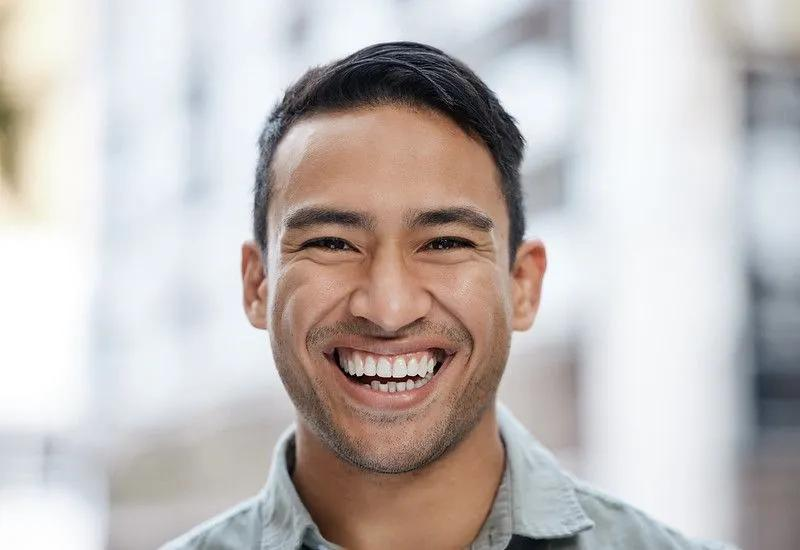


Raw model predictions:
[ClassificationPrediction(score=0.36012914776802063, label_name='Happy', label_index=3)]

Predicted emotion: Happy
Predicted class index: 3
Confidence: 0.36012914776802063

Detected Emotion: HAPPY


### Assistant Response
**You look happy! Keep smiling and enjoy your day.**

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
from google.colab import files
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io

def emotion_assistant():

    print("EMOTION-AWARE COGNITIVE ASSISTANT")
    print("Upload a facial image for emotion analysis.")

    # 1. Upload image
    uploaded = files.upload()

    if not uploaded:
        print("No image uploaded.")
        return

    filename = next(iter(uploaded))

    with Image.open(io.BytesIO(uploaded[filename])) as img:
        image = img.convert("RGB").copy()

    display(image)

    # 2. Run the connected LandingAI model
    predictions = predictor.predict(np.array(image))

    print("\nRaw model predictions:")
    print(predictions)

    if not predictions:
        print("No predictions returned by the model.")
        return

    # 3. Read the ClassificationPrediction object
    prediction = predictions[0]

    predicted_label = getattr(prediction, "label_name", None)
    predicted_index = getattr(prediction, "label_index", None)
    confidence = getattr(prediction, "score", None)

    print("\nPredicted emotion:", predicted_label)
    print("Predicted class index:", predicted_index)
    print("Confidence:", confidence)

    # 4. Interpret the predicted emotion
    emotion = str(predicted_label).strip().lower() if predicted_label else ""

    emotion_responses = {
        "angry": "You appear to be angry. Take a deep breath and give yourself a moment to relax.",
        "disgust": "Your facial expression appears to show disgust.",
        "fear": "You appear to be showing fear. Take a slow breath. You are doing okay.",
        "happy": "You look happy! Keep smiling and enjoy your day.",
        "sad": "You appear to be sad. Remember to take care of yourself.",
        "surprise": "You look surprised! Something unexpected must have happened.",
        "neutral": "Your facial expression appears neutral."
    }

    if emotion in emotion_responses:
        result = emotion_responses[emotion]
        print("\nDetected Emotion:", emotion.upper())
    else:
        result = "Unable to determine the emotion."
        print("\nUnknown emotion label.")

    # 5. Display assistant response
    display(Markdown(f"### Assistant Response\n**{result}**"))

    # 6. Generate audio response
    if emotion in emotion_responses:

        speech = gTTS(text=result, lang="en")
        speech.save("emotion_response.mp3")

        display(Audio("emotion_response.mp3", autoplay=False))

        files.download("emotion_response.mp3")


# Run the assistant
emotion_assistant()